# Minimax và Alpha-Beta - Caro 11×11

**Người phụ trách:** Lê Ngọc Phúc · **Tài liệu phân công:** `docs/Ngoc-Phuc.md`

| Giai đoạn | Phần notebook | Trạng thái |
| :--- | :--- | :--- |
| 1 - Trạng thái tìm kiếm và hàm lượng giá | 1-4 | Hoàn thành (PR #17) |
| 2 - Minimax, Alpha-Beta, Iterative Deepening | 5-6 | Đang thực hiện |
| 3 - Đối chứng cắt tỉa, khảo sát độ sâu, thi đấu | 7-10 | Chưa thực hiện |

Notebook chỉ tổ chức thí nghiệm; toàn bộ thuật toán được import từ `agents/minimax_agent.py`.
Chạy lại bằng **Restart Kernel → Run All**.

## 1. Câu hỏi nghiên cứu và phạm vi

**Câu hỏi chính (trả lời ở Giai đoạn 2-3):** Alpha-Beta giúp giảm bao nhiêu phần trăm số nút duyệt
và thời gian tính toán so với Minimax thuần khi giữ nguyên chất lượng nước đi ở cùng độ sâu?

Để câu hỏi này có ý nghĩa, hai biến thể phải dùng **chung** một tầng trạng thái, một hàm lượng giá
và một tập nước ứng viên. Giai đoạn 1 xây dựng và kiểm chứng phần nền tảng chung đó:

1. **Trạng thái tìm kiếm** (`SearchState`): chuyển trạng thái và phát hiện kết thúc phải khớp Game Engine;
   duyệt nước con không được làm thay đổi trạng thái cha.
2. **Hàm lượng giá** (`evaluate`): thống nhất góc nhìn, điểm terminal luôn vượt trội điểm heuristic.

Giai đoạn 2 xây dựng thuật toán trên nền tảng đó và kiểm chứng tính nhất quán:

3. **Minimax giới hạn độ sâu** (`MinimaxSearcher`) với **Alpha-Beta bật/tắt**, cùng trạng thái, lượng giá,
   tập ứng viên và thứ tự xét nước.
4. **Tác tử** `MinimaxAgent`: chế độ `fixed` (độ sâu cố định) và `time` (Iterative Deepening, dừng trước hạn).

**Ngoài phạm vi notebook hiện tại:** khảo sát độ sâu, thi đấu nhiều ván và phân tích thất bại (Giai đoạn 3).

In [1]:
from pathlib import Path
import os

# Chuyển về thư mục Caro để import module chung từ vị trí notebook.
if Path.cwd().name == 'notebooks' and (Path.cwd().parent / 'core').is_dir():
    os.chdir(Path.cwd().parent)
if not (Path.cwd() / 'core' / 'game_engine.py').is_file():
    raise RuntimeError('Hãy mở notebook từ thư mục caro-11x11 hoặc notebooks')

import platform
import sys
from functools import partial
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd

from agents.minimax_agent import (DEFAULT_TIME_MARGIN_S, WIN_SCORE, WINDOW_WEIGHTS, MinimaxAgent,
                                  MinimaxSearcher, SearchState, evaluate, heuristic_bound,
                                  heuristic_score, terminal_score, window_counts)
from agents.random_agent import RandomAgent
from config.game_config import BOARD_SIZE, WIN_LENGTH
from config.search_budget import SearchBudget
from core import CaroGame
from evaluation.match import play_match
from evaluation.metrics import summarize_latencies

X, O = 1, -1
print('Đã import module agents.minimax_agent từ', Path('agents/minimax_agent.py').resolve())

Đã import module agents.minimax_agent từ D:\TTNT_NC\AdvancedAI-Repo\caro-11x11\agents\minimax_agent.py


## 2. Môi trường và cấu hình

Toàn bộ cấu hình tập trung ở cell dưới. Thí nghiệm nào đổi cấu hình sẽ ghi rõ ngay tại phần đó.

In [2]:
CONFIG = {
    'Kích thước bàn': BOARD_SIZE,
    'Số quân liên tiếp để thắng': WIN_LENGTH,
    'Bán kính ứng viên (candidate_actions)': 2,
    'Trọng số cửa sổ theo số quân 0..5': WINDOW_WEIGHTS,
    'Điểm terminal (WIN_SCORE)': WIN_SCORE,
    'Cận trên |heuristic|': heuristic_bound(),
    'Độ sâu chế độ fixed (ply)': SearchBudget().depth,
    'Giới hạn thời gian chế độ time (giây)': SearchBudget(mode='time').time_limit_s,
    'Biên dừng sớm chế độ time (giây)': DEFAULT_TIME_MARGIN_S,
    'Thứ tự xét nước': 'hàng rồi cột của candidate_actions; tùy chọn sắp theo heuristic (nút còn >= 2 ply)',
    'Phá hòa': 'giữ nước đồng điểm gặp đầu tiên theo thứ tự xét',
    'Seed ván ngẫu nhiên (Phần 3)': list(range(20)),
    'Vị trí đối chứng (Phần 6)': 'seed 0-4 với 10/14/18/22/26 nước ngẫu nhiên + thế "X phải chặn"',
    'Ván kiểm tra deadline (Phần 6.1)': '4 ván Minimax time 2,0 s với Random seed 0 và 1, Minimax lần lượt cầm X và O',
}
HARDWARE = {
    'Hệ điều hành': platform.platform(),
    'CPU': platform.processor() or 'không xác định',
    'Số luồng CPU': os.cpu_count(),
    'Python': sys.version.split()[0],
    'NumPy': np.__version__,
}
display(pd.DataFrame({'Giá trị': {k: str(v) for k, v in CONFIG.items()}}))
display(pd.DataFrame({'Giá trị': {k: str(v) for k, v in HARDWARE.items()}}))

,Giá trị
Kích thước bàn,11
Số quân liên tiếp để thắng,5
Bán kính ứng viên (candidate_actions),2
Trọng số cửa sổ theo số quân 0..5,"(0, 1, 10, 100, 1000, 0)"
Điểm terminal (WIN_SCORE),10000000
Cận trên |heuristic|,252000
Độ sâu chế độ fixed (ply),2
Giới hạn thời gian chế độ time (giây),2.0
Biên dừng sớm chế độ time (giây),0.1
Thứ tự xét nước,hàng rồi cột của candidate_actions; tùy chọn s...


,Giá trị
Hệ điều hành,Windows-10-10.0.26200-SP0
CPU,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
Số luồng CPU,16
Python,3.11.9
NumPy,2.4.6


**Nhận xét:** Phần cứng chỉ ảnh hưởng thời gian chạy và độ sâu đạt được ở chế độ `time`; giá trị tìm kiếm,
nước đi và số nút ở chế độ `fixed` là tất định (không phụ thuộc máy). Seed chỉ dùng để sinh vị trí và nước của Random.

## 3. Kiểm chứng trạng thái tìm kiếm

**Thiết kế:** `SearchState` giữ bản sao bàn cờ riêng; `apply(action)` trả về **đối tượng mới**,
nên trạng thái cha bất biến. Phát hiện thắng chỉ xét 4 đường qua nước vừa đi (giống `CaroGame.check_winner`);
hòa khi bàn đầy. Khi ván kết thúc, `current_player` giữ người vừa đi nước cuối - đúng quy ước engine.

**Thí nghiệm:** chạy cùng một chuỗi nước trên engine và trên `SearchState`, so sánh **sau từng nước**
5 trường: bàn cờ, người đến lượt, nước cuối, số nước, kết quả.

**Kỳ vọng:** khớp 100% ở mọi bước, cho cả X và O, 4 hướng, chuỗi 5 và chuỗi 6, ván hòa và ván ngẫu nhiên.

In [3]:
DIRECTIONS = {'ngang': ((0, 1), (5, 1)), 'dọc': ((1, 0), (1, 5)),
              'chéo chính': ((1, 1), (1, 1)), 'chéo phụ': ((1, -1), (1, 9))}

def interleave(x_moves, o_moves):
    moves = []
    for i, x in enumerate(x_moves):
        moves.append(x)
        if i < len(o_moves):
            moves.append(o_moves[i])
    return moves

def winning_sequence(winner, direction, length):
    # Chuỗi 6: đi ô thứ 4 cuối cùng để nối hai đoạn 3 + 2 thành 6.
    (dr, dc), (r0, c0) = DIRECTIONS[direction]
    line = [(r0 + k * dr, c0 + k * dc) for k in range(length)]
    if length == 6:
        line = line[:3] + line[4:] + [line[3]]
    filler = [(r, c) for r in range(0, 11, 2) for c in range(0, 11, 2) if (r, c) not in line]
    return interleave(line, filler[:length - 1]) if winner == X else interleave(filler[:length], line)

def draw_sequence():
    x_cells = [(r, c) for r in range(11) for c in range(11) if (c + r // 2) % 2 == 0]
    o_cells = [(r, c) for r in range(11) for c in range(11) if (c + r // 2) % 2 == 1]
    return interleave(x_cells, o_cells)

def random_sequence(seed):
    game, agents = CaroGame(), {X: RandomAgent(seed), O: RandomAgent(seed + 100)}
    moves = []
    while not game.is_terminal():
        action = agents[game.current_player].choose_action(game.board, game.current_player)
        game.step(action)
        moves.append(action)
    return moves

def compare_with_engine(moves):
    game, state = CaroGame(), SearchState.initial()
    mismatches = 0
    for move in moves:
        game.step(move)
        state = state.apply(move)
        same = (np.array_equal(state.board, game.board)
                and state.current_player == game.current_player
                and state.last_action == game.last_action
                and state.move_count == game.move_count
                and state.result() == game.result())
        mismatches += not same
    return game, state, mismatches

cases = {f'{"X" if w == X else "O"} thắng, {d}, chuỗi {n}': winning_sequence(w, d, n)
         for w in (X, O) for d in DIRECTIONS for n in (5, 6)}
cases['Hòa, bàn đầy 61 X / 60 O'] = draw_sequence()
cases.update({f'Ngẫu nhiên seed {s}': random_sequence(s) for s in CONFIG['Seed ván ngẫu nhiên (Phần 3)']})

label = {None: 'đang chơi', 1: 'X thắng', -1: 'O thắng', 0: 'hòa'}
rows = []
for name, moves in cases.items():
    game, state, mismatches = compare_with_engine(moves)
    rows.append({'Tình huống': name, 'Số nước': len(moves), 'Engine': label[game.result()],
                 'SearchState': label[state.result()], 'Số bước lệch': mismatches})
table = pd.DataFrame(rows)
display(table)
print(f'Tổng: {len(table)} chuỗi, {table["Số nước"].sum()} bước so sánh, '
      f'{table["Số bước lệch"].sum()} bước lệch.')

,Tình huống,Số nước,Engine,SearchState,Số bước lệch
0,"X thắng, ngang, chuỗi 5",9,X thắng,X thắng,0
1,"X thắng, ngang, chuỗi 6",11,X thắng,X thắng,0
2,"X thắng, dọc, chuỗi 5",9,X thắng,X thắng,0
3,"X thắng, dọc, chuỗi 6",11,X thắng,X thắng,0
4,"X thắng, chéo chính, chuỗi 5",9,X thắng,X thắng,0
5,"X thắng, chéo chính, chuỗi 6",11,X thắng,X thắng,0
6,"X thắng, chéo phụ, chuỗi 5",9,X thắng,X thắng,0
7,"X thắng, chéo phụ, chuỗi 6",11,X thắng,X thắng,0
8,"O thắng, ngang, chuỗi 5",10,O thắng,O thắng,0
9,"O thắng, ngang, chuỗi 6",12,O thắng,O thắng,0


Tổng: 37 chuỗi, 1768 bước so sánh, 0 bước lệch.


In [4]:
# Tính độc lập trạng thái: duyệt mọi nước con (và 5 nước cháu mỗi con) rồi kiểm tra cha.
game = CaroGame()
for move in random_sequence(7)[:12]:
    game.step(move)
input_board = game.board.copy()
parent = SearchState(input_board, game.current_player)
snapshot = (parent.board.copy(), parent.current_player, parent.last_action, parent.move_count, parent.result())

n_children = 0
for action in parent.candidates():
    child = parent.apply(action)
    n_children += 1
    for grandchild_action in child.candidates()[:5]:
        child.apply(grandchild_action)
        n_children += 1

unchanged = (np.array_equal(parent.board, snapshot[0])
             and (parent.current_player, parent.last_action, parent.move_count, parent.result()) == snapshot[1:])
print(f'Đã sinh {n_children} trạng thái con/cháu từ {len(parent.candidates())} ứng viên.')
print('Trạng thái cha giữ nguyên:', unchanged)
print('Mảng board đầu vào giữ nguyên:', np.array_equal(input_board, game.board))

Đã sinh 468 trạng thái con/cháu từ 78 ứng viên.
Trạng thái cha giữ nguyên: True
Mảng board đầu vào giữ nguyên: True


**Nhận xét:** Bảng trên cho thấy số bước lệch của từng chuỗi; tổng số bước lệch ở dòng in cuối là
kết quả đối chiếu thực tế. Các chuỗi chuỗi-6 xác nhận luật freestyle (dài hơn 5 vẫn thắng) và chuỗi hòa
xác nhận phát hiện bàn đầy. Cell thứ hai xác nhận việc duyệt cây không làm biến dạng trạng thái cha.
Các kiểm tra này cũng có trong `tests/test_minimax_agent.py`; notebook chỉ minh họa, không thay unit test.

## 4. Giải thích hàm lượng giá

### 4.1 Quy ước góc nhìn và thang điểm

`evaluate(state, perspective)` trả điểm **theo góc nhìn bên `perspective`**: dương là có lợi cho bên đó.
Đổi góc nhìn chỉ đổi dấu: `evaluate(s, X) == -evaluate(s, O)`.

| Loại trạng thái | Điểm theo góc nhìn `perspective` |
| :--- | :--- |
| Terminal - `perspective` thắng | `+WIN_SCORE` = +10 000 000 |
| Terminal - `perspective` thua | `−WIN_SCORE` = −10 000 000 |
| Terminal - hòa | 0 |
| Chưa kết thúc | heuristic, luôn nằm trong `[−heuristic_bound, +heuristic_bound]` |

Terminal và heuristic tách thành hai hàm (`terminal_score`, `heuristic_score`); `evaluate` kiểm tra terminal trước.

In [5]:
bound = heuristic_bound()
print(f'Số cửa sổ 5 ô trên bàn {BOARD_SIZE}×{BOARD_SIZE}: {bound // max(WINDOW_WEIGHTS)}')
print(f'Cận trên |heuristic| = số cửa sổ × trọng số lớn nhất = {bound:,}')
print(f'WIN_SCORE = {WIN_SCORE:,} - gấp {WIN_SCORE / bound:.1f} lần cận trên heuristic')
print('terminal_score: X thắng nhìn từ X =', terminal_score(1, X), '| từ O =', terminal_score(1, O),
      '| hòa =', terminal_score(0, X))

Số cửa sổ 5 ô trên bàn 11×11: 252
Cận trên |heuristic| = số cửa sổ × trọng số lớn nhất = 252,000
WIN_SCORE = 10,000,000 - gấp 39.7 lần cận trên heuristic
terminal_score: X thắng nhìn từ X = 10000000 | từ O = -10000000 | hòa = 0


### 4.2 Thành phần heuristic: cửa sổ 5 ô

Mỗi **cửa sổ** là một đoạn 5 ô liên tiếp theo một trong 4 hướng (252 cửa sổ trên bàn 11×11).
Một cửa sổ **còn sống** với X nếu không chứa quân O - X vẫn có thể lấp đủ cửa sổ đó để thắng.

$$h(\text{board}, p) = p \cdot \Big(\sum_{w\ \text{sống với X}} W[\#X(w)] - \sum_{w\ \text{sống với O}} W[\#O(w)]\Big)$$

với trọng số `W = (0, 1, 10, 100, 1000, 0)` theo số quân trong cửa sổ.

**Lý do chọn:**
- Cửa sổ bị đối thủ chiếm một ô không bao giờ thành chuỗi thắng → không tính cho ai. Đây là cách tự nhiên
  để phân biệt chuỗi **mở** (nhiều cửa sổ sống) với chuỗi **bị chặn** (ít cửa sổ sống).
- Mỗi quân thêm vào cửa sổ nhân điểm lên 10: một cửa sổ còn thiếu 1 quân (gần thắng) nặng hơn
  vài cửa sổ yếu hơn cộng lại.
- Cửa sổ đủ 5 quân là terminal → trọng số 0, giao cho `terminal_score`.
- Cửa sổ nhận cả chuỗi có khoảng trống (ví dụ `X X . X X` là cửa sổ 4 quân), điều mà đếm quân liền kề bỏ sót.

Hình dưới đếm số cửa sổ đi qua từng ô = điểm của **một quân đơn lẻ** đặt tại ô đó (trọng số 1 quân = 1).

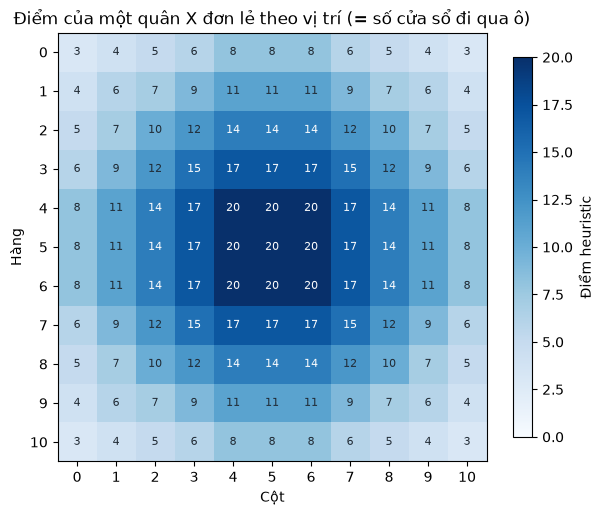

Tâm: 20 | góc: 3 | giữa mép: 8


In [6]:
coverage = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=int)
for r in range(BOARD_SIZE):
    for c in range(BOARD_SIZE):
        board = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=np.int8)
        board[r, c] = X
        coverage[r, c] = heuristic_score(board, X)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
image = ax.imshow(coverage, cmap='Blues', vmin=0)
for r in range(BOARD_SIZE):
    for c in range(BOARD_SIZE):
        ax.text(c, r, coverage[r, c], ha='center', va='center', fontsize=8,
                color='white' if coverage[r, c] > coverage.max() * 0.6 else '#1f2933')
ax.set_xticks(range(BOARD_SIZE))
ax.set_yticks(range(BOARD_SIZE))
ax.set_xlabel('Cột')
ax.set_ylabel('Hàng')
ax.set_title('Điểm của một quân X đơn lẻ theo vị trí (= số cửa sổ đi qua ô)')
fig.colorbar(image, ax=ax, shrink=0.8, label='Điểm heuristic')
plt.tight_layout()
plt.show()
print('Tâm:', coverage[5, 5], '| góc:', coverage[0, 0], '| giữa mép:', coverage[0, 5])

**Nhận xét:** Không cần thêm bảng điểm vị trí riêng - trọng số cửa sổ tự tạo ưu tiên trung tâm
(ô tâm nằm trong 20 cửa sổ, góc chỉ 3), vì quân ở trung tâm có nhiều hướng phát triển hơn.
Cả vùng 3×3 quanh tâm (hàng/cột 4–6) cùng đạt 20: trên bàn 11×11, các ô này đều đủ chỗ cho cả 5 vị trí
cửa sổ ở mọi hướng, nên heuristic **không** phân biệt chúng - thứ tự xét nước sẽ quyết định khi đồng điểm.

### 4.3 Đối chiếu vị trí tốt/xấu cho cả X và O

Mỗi mẫu được đặt ở giữa hàng 5. Với mỗi mẫu, xét hai trường hợp: X sở hữu mẫu, và O sở hữu mẫu
y hệt (đổi màu). Kỳ vọng:
- Điểm tăng theo độ mạnh của mẫu: 2 mở < 3 bị chặn < 3 mở < 4 bị chặn < 4 mở.
- Cột "X sở hữu, nhìn từ X" bằng cột "O sở hữu, nhìn từ O" (đối xứng màu), và nhìn từ đối thủ thì đổi dấu.

In [7]:
PATTERNS = {  # (ô của chủ mẫu, ô của đối thủ) trên hàng 5
    '2 mở':            ([4, 5], []),
    '3 bị chặn 1 đầu': ([4, 5, 6], [3]),
    '3 mở':            ([4, 5, 6], []),
    '3 có khe (X X . X)': ([3, 4, 6], []),
    '4 bị chặn 1 đầu': ([3, 4, 5, 6], [2]),
    '4 mở':            ([3, 4, 5, 6], []),
    '5 - thắng':       ([3, 4, 5, 6, 7], []),
}

def pattern_board(owner, own_cols, opp_cols):
    board = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=np.int8)
    board[5, own_cols] = owner
    board[5, opp_cols] = -owner
    return board

rows = []
for name, (own, opp) in PATTERNS.items():
    s_x = SearchState(pattern_board(X, own, opp), O)
    s_o = SearchState(pattern_board(O, own, opp), X)
    rows.append({'Mẫu': name,
                 'X sở hữu, nhìn từ X': evaluate(s_x, X), 'X sở hữu, nhìn từ O': evaluate(s_x, O),
                 'O sở hữu, nhìn từ O': evaluate(s_o, O), 'O sở hữu, nhìn từ X': evaluate(s_o, X)})
patterns = pd.DataFrame(rows).set_index('Mẫu')
display(patterns)

strength = ['2 mở', '3 bị chặn 1 đầu', '3 mở', '4 bị chặn 1 đầu', '4 mở', '5 - thắng']
ordered = patterns.loc[strength, 'X sở hữu, nhìn từ X'].tolist()
print('Điểm tăng chặt theo độ mạnh mẫu:', all(a < b for a, b in zip(ordered, ordered[1:])))
print('Đối xứng màu (X nhìn từ X == O nhìn từ O):',
      patterns['X sở hữu, nhìn từ X'].equals(patterns['O sở hữu, nhìn từ O']))
print('Đổi góc nhìn đổi dấu:',
      (patterns['X sở hữu, nhìn từ X'] == -patterns['X sở hữu, nhìn từ O']).all())

,"X sở hữu, nhìn từ X","X sở hữu, nhìn từ O","O sở hữu, nhìn từ O","O sở hữu, nhìn từ X"
Mẫu,,,,
2 mở,72,-72,72,-72
3 bị chặn 1 đầu,143,-143,143,-143
3 mở,367,-367,367,-367
3 có khe (X X . X),275,-275,275,-275
4 bị chặn 1 đầu,1158,-1158,1158,-1158
4 mở,2279,-2279,2279,-2279
5 - thắng,10000000,-10000000,10000000,-10000000


Điểm tăng chặt theo độ mạnh mẫu: True
Đối xứng màu (X nhìn từ X == O nhìn từ O): True
Đổi góc nhìn đổi dấu: True


In [8]:
def show(board):
    symbols = {0: '.', 1: 'X', -1: 'O'}
    print('   ' + ' '.join(f'{c:>2}' for c in range(board.shape[1])))
    for r, row in enumerate(board):
        print(f'{r:>2} ' + ' '.join(f'{symbols[int(v)]:>2}' for v in row))

for name in ('3 mở', '4 bị chặn 1 đầu'):
    print(f'Mẫu "{name}" của X - điểm nhìn từ X: {patterns.loc[name, "X sở hữu, nhìn từ X"]}')
    show(pattern_board(X, *PATTERNS[name]))
    print()

Mẫu "3 mở" của X - điểm nhìn từ X: 367
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  .  .  X  X  X  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .

Mẫu "4 bị chặn 1 đầu" của X - điểm nhìn từ X: 1158
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  O  X  X  X  X  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  .  .  .  .  .  .  .  .  .  .  .
10  .  .  .  .  .  .  .  .  .  .  .



**Nhận xét:** Bảng 4.3 là kết quả chạy thực tế, không nhập tay. Các dòng kiểm tra in ra cho biết thứ tự điểm
có đúng kỳ vọng hay không. Mẫu "3 có khe" (`X X . X`) vẫn được nhận diện là thế 3 nhờ cách đếm theo cửa sổ:
điểm của nó nằm giữa "3 bị chặn" và "3 mở" vì có ít cửa sổ chứa đủ cả 3 quân hơn chuỗi 3 liền.

### 4.4 Hạn chế đã biết của hàm lượng giá
- **Không xét lượt đi:** hai bên cùng có "4 mở" cho điểm bằng nhau dù bên đến lượt thắng ngay. Giai đoạn 2 giao việc này
  cho tìm kiếm (độ sâu ≥ 1 sẽ thấy nước thắng).
- **Không nhận diện đe dọa kép** (ví dụ 4 + 3 mở) như một mẫu riêng; điểm chỉ là tổng cộng tuyến tính.
- **Trọng số theo cấp số 10** là lựa chọn thiết kế có lý do nhưng chưa tinh chỉnh bằng thực nghiệm; Giai đoạn 3 không dùng
  ván đánh giá cuối để chỉnh tham số.

## 5. Quan sát cây Minimax

**Quy ước:** một ply là một nước của một bên. Nút gốc là **Max** (bên đến lượt ở gốc), nút mà đối thủ đến lượt là
**Min**. Mọi điểm tính theo góc nhìn bên ở gốc. Nút terminal không mở rộng; thắng ở ply `p` được `WIN_SCORE - p`
(thắng sớm tốt hơn), thua được `-(WIN_SCORE - p)` (thua muộn tốt hơn).

**Thí nghiệm 5.1:** cây nhỏ độ sâu 2, bán kính ứng viên **1** (để cây đủ nhỏ để in toàn bộ), Minimax thuần,
không sắp xếp. Bàn cờ: X (5,5), O (5,6), X (6,5); O đến lượt nên O là Max.

**Kỳ vọng:** giá trị mỗi nước gốc = **min** điểm lá của các nước đáp trả; giá trị gốc = **max** các giá trị đó;
`MinimaxSearcher` cho đúng giá trị gốc này. Chạy Alpha-Beta trên cùng cây (cùng độ sâu, bán kính,
thứ tự xét) phải cho cùng giá trị gốc và cùng nước, với số nút không nhiều hơn.

In [9]:
TREE_MOVES = [(5, 5), (5, 6), (6, 5)]
TREE_RADIUS, TREE_DEPTH = 1, 2

tree_game = CaroGame()
for move in TREE_MOVES:
    tree_game.step(move)
tree_root = SearchState(tree_game.board, tree_game.current_player)
root_player = tree_root.current_player

rows, leaf_tables = [], {}
for action in tree_root.candidates(TREE_RADIUS):
    child = tree_root.apply(action)
    leaves = {reply: evaluate(child.apply(reply), root_player) for reply in child.candidates(TREE_RADIUS)}
    worst_reply = min(leaves, key=leaves.get)
    leaf_tables[action] = leaves
    rows.append({'Nước gốc (Max)': action, 'Số nước đáp trả': len(leaves),
                 'Lá nhỏ nhất (Min chọn)': leaves[worst_reply], 'Nước đáp trả của Min': worst_reply,
                 'Lá lớn nhất': max(leaves.values())})
tree_table = pd.DataFrame(rows)
best_row = tree_table['Lá nhỏ nhất (Min chọn)'].idxmax()
display(tree_table)

result = MinimaxSearcher(use_alpha_beta=False, move_ordering=False, radius=TREE_RADIUS).search(tree_root, TREE_DEPTH)
print('Bên đến lượt ở gốc (Max):', 'X' if root_player == X else 'O')
print('Tính tay: giá trị gốc =', tree_table.loc[best_row, 'Lá nhỏ nhất (Min chọn)'],
      '| nước =', tree_table.loc[best_row, 'Nước gốc (Max)'])
print('MinimaxSearcher: giá trị gốc =', result.value, '| nước =', result.action,
      '| số nút =', result.nodes_visited)

# Đối chứng Alpha-Beta trên cùng cây nhỏ: cùng độ sâu, bán kính, thứ tự xét, không sắp xếp.
tree_ab = MinimaxSearcher(use_alpha_beta=True, move_ordering=False, radius=TREE_RADIUS).search(tree_root, TREE_DEPTH)
display(pd.DataFrame([
    {'Chế độ': 'Minimax thuần', 'Giá trị gốc': result.value, 'Nước chọn': result.action,
     'Số nút': result.nodes_visited, 'Số lần cắt tỉa': result.pruned_nodes},
    {'Chế độ': 'Alpha-Beta', 'Giá trị gốc': tree_ab.value, 'Nước chọn': tree_ab.action,
     'Số nút': tree_ab.nodes_visited, 'Số lần cắt tỉa': tree_ab.pruned_nodes},
]).set_index('Chế độ'))
print('Alpha-Beta cùng giá trị gốc:', tree_ab.value == result.value, '| cùng nước:', tree_ab.action == result.action,
      f'| giảm nút: {100 * (1 - tree_ab.nodes_visited / result.nodes_visited):.1f}%')

,Nước gốc (Max),Số nước đáp trả,Lá nhỏ nhất (Min chọn),Nước đáp trả của Min,Lá lớn nhất
0,"(4, 4)",16,-327,"(4, 5)",-44
1,"(4, 5)",14,-85,"(7, 5)",13
2,"(4, 6)",14,-295,"(4, 5)",-12
3,"(4, 7)",16,-325,"(4, 5)",-42
4,"(5, 4)",14,-330,"(4, 5)",-49
5,"(5, 7)",14,-325,"(4, 5)",-44
6,"(6, 4)",14,-327,"(4, 5)",-44
7,"(6, 6)",12,-295,"(4, 5)",-12
8,"(6, 7)",15,-325,"(4, 5)",-15
9,"(7, 4)",16,-333,"(4, 5)",-47


Bên đến lượt ở gốc (Max): O
Tính tay: giá trị gốc = -85 | nước = (4, 5)
MinimaxSearcher: giá trị gốc = -85 | nước = (4, 5) | số nút = 187


,Giá trị gốc,Nước chọn,Số nút,Số lần cắt tỉa
Chế độ,,,,
Minimax thuần,-85,"(4, 5)",187,0
Alpha-Beta,-85,"(4, 5)",64,10


Alpha-Beta cùng giá trị gốc: True | cùng nước: True | giảm nút: 65.8%


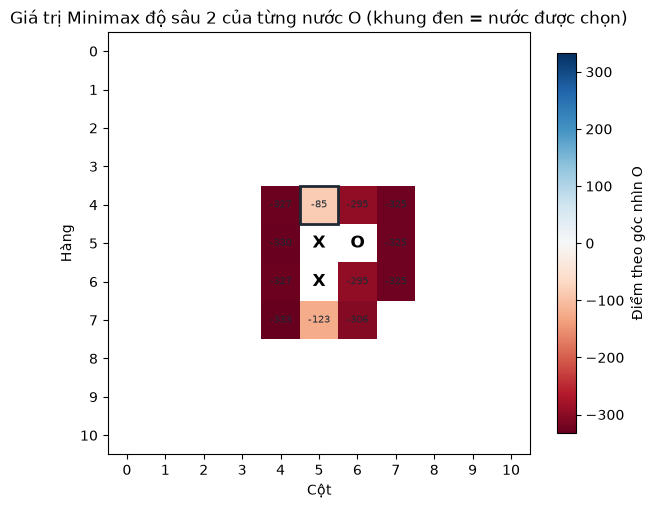

Các lá dưới nước được chọn (4, 5) (5 lá nhỏ nhất, Min sẽ chọn lá đầu tiên):


Điểm lá
7 5      -85
6 4      -57
  6      -57
  7      -41
5 4      -30

In [10]:
# Bản đồ giá trị Minimax của từng nước gốc (màu phân kỳ quanh 0: xanh có lợi cho O, đỏ có lợi cho X).
grid = np.full((BOARD_SIZE, BOARD_SIZE), np.nan)
for _, row in tree_table.iterrows():
    grid[row['Nước gốc (Max)']] = row['Lá nhỏ nhất (Min chọn)']
lo, hi = np.nanmin(grid), np.nanmax(grid)
span = max(abs(lo), abs(hi), 1)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
image = ax.imshow(grid, cmap='RdBu', norm=TwoSlopeNorm(vcenter=0, vmin=-span, vmax=span))
for (r, c), v in np.ndenumerate(tree_game.board):
    if v:
        ax.text(c, r, 'X' if v == X else 'O', ha='center', va='center', fontsize=12, fontweight='bold')
    elif not np.isnan(grid[r, c]):
        ax.text(c, r, int(grid[r, c]), ha='center', va='center', fontsize=7, color='#1f2933')
r, c = result.action
ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, lw=2, ec='#1f2933'))
ax.set_xticks(range(BOARD_SIZE))
ax.set_yticks(range(BOARD_SIZE))
ax.set_xlabel('Cột')
ax.set_ylabel('Hàng')
ax.set_title('Giá trị Minimax độ sâu 2 của từng nước O (khung đen = nước được chọn)')
fig.colorbar(image, ax=ax, shrink=0.8, label='Điểm theo góc nhìn O')
plt.tight_layout()
plt.show()

chosen_leaves = pd.Series(leaf_tables[result.action], name='Điểm lá').sort_values()
print(f'Các lá dưới nước được chọn {result.action} (5 lá nhỏ nhất, Min sẽ chọn lá đầu tiên):')
display(chosen_leaves.head().to_frame())

**Thí nghiệm 5.2 - tầm nhìn theo độ sâu:** thế "X phải chặn". O có 4 quân ở hàng 5 (cột 3-6), đầu trái (5,2)
đã bị X chặn, nên nếu X không đi (5,7) thì O thắng ở đó. **X đến lượt** nên X là Max. Minimax thuần, không
sắp xếp, bán kính 2; bàn cờ được in ngay dưới.

Ở độ sâu 1, Max chỉ thấy điểm heuristic sau nước của mình; ở độ sâu 2, Max thấy được nước thắng của O ở ply 2.

**Kỳ vọng:** độ sâu 2 chọn (5,7) và giá trị gốc không phải điểm thua; mọi nước không chặn đều dẫn tới O thắng
ở ply 2. Độ sâu 1 không nhìn tới ply 2 nên lựa chọn của nó chỉ dựa vào heuristic.

In [11]:
BLOCK_X = [(5, 2), (5, 3), (9, 0), (5, 4), (9, 4), (5, 5), (9, 8), (5, 6)]  # X và O xen kẽ, X đi trước
block_game = CaroGame()
for move in BLOCK_X:
    block_game.step(move)
block_state = SearchState(block_game.board, block_game.current_player)
print('Bên đến lượt:', 'X' if block_state.current_player == X else 'O')
show(block_game.board)
print()
rows = []
for depth in (1, 2):
    res = MinimaxSearcher(use_alpha_beta=False, move_ordering=False).search(block_state, depth)
    rows.append({'Độ sâu': depth, 'Nước chọn': res.action, 'Giá trị gốc': res.value,
                 'Chặn đúng (5,7)': res.action == (5, 7), 'Số nút': res.nodes_visited})
display(pd.DataFrame(rows))

# Nước không chặn nào để O thắng ngay ở ply 2? (độ sâu 1 không nhìn tới ply này)
non_block = [a for a in block_state.candidates() if a != (5, 7)]
losing = [a for a in non_block
          if any(block_state.apply(a).apply(r).result() == O for r in block_state.apply(a).candidates())]
print(f'Số nước không chặn dẫn tới O thắng ở ply 2: {len(losing)}/{len(non_block)}')

Bên đến lượt: X
    0  1  2  3  4  5  6  7  8  9 10
 0  .  .  .  .  .  .  .  .  .  .  .
 1  .  .  .  .  .  .  .  .  .  .  .
 2  .  .  .  .  .  .  .  .  .  .  .
 3  .  .  .  .  .  .  .  .  .  .  .
 4  .  .  .  .  .  .  .  .  .  .  .
 5  .  .  X  O  O  O  O  .  .  .  .
 6  .  .  .  .  .  .  .  .  .  .  .
 7  .  .  .  .  .  .  .  .  .  .  .
 8  .  .  .  .  .  .  .  .  .  .  .
 9  X  .  .  .  X  .  .  .  X  .  .
10  .  .  .  .  .  .  .  .  .  .  .



,Độ sâu,Nước chọn,Giá trị gốc,"Chặn đúng (5,7)",Số nút
0,1,"(5, 7)",4,True,73
1,2,"(5, 7)",-112,True,5374


Số nước không chặn dẫn tới O thắng ở ply 2: 71/71


**Nhận xét:** Bảng 5.1 và dòng "Tính tay" cho phép đối chiếu trực tiếp cách Max/Min lan truyền giá trị từ lá lên gốc
với kết quả của `MinimaxSearcher`. Trên cùng cây này, Alpha-Beta cho đúng giá trị gốc và nước đi của
Minimax thuần nhưng duyệt ít nút hơn (bảng đối chứng ngay dưới bảng 5.1); đây là kiểm chứng tính nhất quán
trên cây nhỏ, còn phần 6 lặp lại phép so sánh trên các thế cờ lớn hơn. Bản đồ màu cho thấy các nước sát cụm quân có giá trị khác biệt rõ nhất.
Ở 5.2, độ sâu 1 cũng chọn ô chặn nhưng chỉ nhờ heuristic (đặt quân vào đó làm chết các cửa sổ 4 quân của O);
nó không biết nước này là bắt buộc. Độ sâu 2 thì thấy được mọi nước không chặn đều dẫn tới thua ở ply 2
(dòng đếm phía trên), nên lựa chọn chặn được chứng minh trong tầm tìm kiếm chứ không phụ thuộc trọng số heuristic.

## 6. Đối chứng thực nghiệm Alpha-Beta

**Thiết kế:** trên cùng vị trí, cùng độ sâu, cùng bán kính 2, cùng hàm lượng giá và **cùng thứ tự xét nước**, chạy
Minimax thuần và Alpha-Beta. So sánh giá trị nút gốc, nước đi, số nút duyệt (`nodes_visited`, tính cả gốc), số lần
cắt tỉa (`pruned_nodes`: số lần `alpha >= beta` mà còn ít nhất một nước con chưa xét) và thời gian đo trực tiếp.
Lặp lại cho hai cấu hình thứ tự: không sắp xếp và sắp xếp theo heuristic.

**Kỳ vọng:** giá trị gốc và nước đi trùng khớp 100% (phá hòa theo nước gặp đầu tiên); Alpha-Beta không bao giờ
duyệt nhiều nút hơn. Thời gian chỉ là số liệu tham khảo trên máy này.

In [12]:
def position_from_random(seed, n_moves):
    game, agent = CaroGame(), RandomAgent(seed)
    for _ in range(n_moves):
        game.step(agent.choose_action(game.board, game.current_player))
    return SearchState(game.board, game.current_player)

POSITIONS = {f'seed {s}, {n} nước': position_from_random(s, n) for s, n in zip(range(5), (10, 14, 18, 22, 26))}
POSITIONS['X phải chặn'] = block_state

rows = []
for name, state in POSITIONS.items():
    for depth in (1, 2):
        for ordering in (False, True):
            runs = {}
            for ab in (False, True):
                searcher = MinimaxSearcher(use_alpha_beta=ab, move_ordering=ordering)
                start = perf_counter()
                runs[ab] = (searcher.search(state, depth), perf_counter() - start)
            (plain, t_plain), (pruned, t_ab) = runs[False], runs[True]
            rows.append({'Vị trí': name, 'Độ sâu': depth, 'Sắp xếp': ordering,
                         'Ứng viên gốc': len(state.candidates()),
                         'Giá trị thuần': plain.value, 'Giá trị AB': pruned.value,
                         'Nước thuần': plain.action, 'Nước AB': pruned.action,
                         'Nút thuần': plain.nodes_visited, 'Nút AB': pruned.nodes_visited,
                         'Cắt tỉa': pruned.pruned_nodes,
                         'Giảm nút (%)': round(100 * (1 - pruned.nodes_visited / plain.nodes_visited), 1),
                         'Thời gian thuần (s)': round(t_plain, 3), 'Thời gian AB (s)': round(t_ab, 3)})
ablation = pd.DataFrame(rows)
display(ablation)
print('Giá trị gốc trùng khớp:', (ablation['Giá trị thuần'] == ablation['Giá trị AB']).all())
print('Nước đi trùng khớp:', (ablation['Nước thuần'] == ablation['Nước AB']).all())
print('Alpha-Beta không duyệt nhiều nút hơn:', (ablation['Nút AB'] <= ablation['Nút thuần']).all())

,Vị trí,Độ sâu,Sắp xếp,Ứng viên gốc,Giá trị thuần,Giá trị AB,Nước thuần,Nước AB,Nút thuần,Nút AB,Cắt tỉa,Giảm nút (%),Thời gian thuần (s),Thời gian AB (s)
0,"seed 0, 10 nước",1,False,94,91,91,"(4, 5)","(4, 5)",95,95,0,0.0,0.002,0.002
1,"seed 0, 10 nước",1,True,94,91,91,"(4, 5)","(4, 5)",95,95,0,0.0,0.002,0.002
2,"seed 0, 10 nước",2,False,94,-14,-14,"(0, 3)","(0, 3)",9003,472,91,94.8,0.197,0.019
3,"seed 0, 10 nước",2,True,94,-14,-14,"(0, 3)","(0, 3)",9003,531,91,94.1,0.196,0.020
4,"seed 1, 14 nước",1,False,100,-44,-44,"(6, 8)","(6, 8)",101,101,0,0.0,0.002,0.002
5,"seed 1, 14 nước",1,True,100,-44,-44,"(6, 8)","(6, 8)",101,101,0,0.0,0.002,0.002
6,"seed 1, 14 nước",2,False,100,-327,-327,"(6, 8)","(6, 8)",10063,4854,92,51.8,0.222,0.111
7,"seed 1, 14 nước",2,True,100,-327,-327,"(6, 8)","(6, 8)",10063,2205,99,78.1,0.221,0.056
8,"seed 2, 18 nước",1,False,98,226,226,"(9, 4)","(9, 4)",99,99,0,0.0,0.002,0.002
9,"seed 2, 18 nước",1,True,98,226,226,"(9, 4)","(9, 4)",99,99,0,0.0,0.002,0.002


Giá trị gốc trùng khớp: True
Nước đi trùng khớp: True
Alpha-Beta không duyệt nhiều nút hơn: True


In [13]:
summary = (ablation.assign(**{'Giảm thời gian (%)': 100 * (1 - ablation['Thời gian AB (s)'] / ablation['Thời gian thuần (s)'])})
           .groupby(['Độ sâu', 'Sắp xếp'])
           .agg(**{'Số vị trí': ('Vị trí', 'count'), 'Nút thuần TB': ('Nút thuần', 'mean'),
                   'Nút AB TB': ('Nút AB', 'mean'), 'Giảm nút TB (%)': ('Giảm nút (%)', 'mean'),
                   'Giảm thời gian TB (%)': ('Giảm thời gian (%)', 'mean')})
           .round(1))
display(summary)

Số vị trí  Nút thuần TB  Nút AB TB  Giảm nút TB (%)  \
Độ sâu Sắp xếp                                                        
1      False            6          93.8       93.8              0.0   
       True             6          93.8       93.8              0.0   
2      False            6        8797.2     2650.7             71.2   
       True             6        8797.2     1444.2             84.6   

                Giảm thời gian TB (%)  
Độ sâu Sắp xếp                         
1      False                     -8.3  
       True                       0.0  
2      False                     68.1  
       True                      80.5

**Nhận xét:** Dòng kiểm tra in ra là kết quả đối chứng thực tế. Ở độ sâu 1 không có cắt tỉa vì nút gốc không có
cận trên (`beta = +vô cực`) nên Alpha-Beta trùng Minimax thuần. Từ độ sâu 2, tỷ lệ giảm nút phụ thuộc thứ tự xét:
khi nước tốt được xét sớm (sắp xếp theo heuristic), cận alpha/beta chặt sớm hơn nên cắt được nhiều hơn.
Thời gian giảm ít hơn số nút vì chi phí sắp xếp và sinh tập ứng viên vẫn phải trả. Khảo sát đầy đủ độ sâu 1/2/3
và nhiều vị trí hơn thuộc Giai đoạn 3.

### 6.1 Kiểm chứng deadline chế độ `time`

**Thiết kế:** 4 ván qua runner chính thức `play_match` (mỗi agent một tiến trình, hạn cứng 2,0 s/nước):
Minimax Alpha-Beta chế độ `time` lần lượt cầm X và O, đối thủ Random seed 0 và 1. Agent tự dừng ở
`2,0 - 0,1 = 1,9 s`. Độ trễ chuẩn là `elapsed_s` do runner đo (tính cả IPC).

**Kỳ vọng:** không có nước nào bị xử thua `timeout`; `elapsed_s` lớn nhất dưới 2,0 s; mỗi nước hoàn tất ít nhất độ sâu 1.

In [14]:
DEADLINE_BUDGET = SearchBudget(mode='time', time_limit_s=2.0)
records, minimax_moves = [], []
if __name__ == '__main__':  # Windows spawn: factory import được từ module .py (MinimaxAgent, RandomAgent)
    for seed in (0, 1):
        for minimax_side in (X, O):
            random_name = f'Random seed {seed}'
            factories = {minimax_side: MinimaxAgent, -minimax_side: partial(RandomAgent, seed)}
            names = {minimax_side: 'Minimax AB (time)', -minimax_side: random_name}
            record, logs = play_match(factories[X], factories[O], agent_x=names[X], agent_o=names[O],
                                      budget=DEADLINE_BUDGET)
            records.append(record)
            minimax_moves += [log for log in logs if log['player'] == minimax_side and log['status'] == 'move']

result_label = {1: 'X thắng', -1: 'O thắng', 0: 'hòa'}
display(pd.DataFrame([{'X': r.agent_x, 'O': r.agent_o, 'Kết quả': result_label[r.winner], 'Lý do': r.reason}
                      for r in records]))
elapsed = [log['elapsed_s'] for log in minimax_moves]
latency = summarize_latencies(elapsed)
print(f"Số nước của Minimax: {latency['count']} | elapsed TB {latency['mean_s']:.3f} s | "
      f"p95 {latency['p95_s']:.3f} s | lớn nhất {max(elapsed):.3f} s | hạn cứng {DEADLINE_BUDGET.time_limit_s} s")
print('Số ván bị xử thua do timeout/lỗi:', sum(r.reason != 'completed' for r in records))
depths = pd.Series([log['stats']['depth_reached'] for log in minimax_moves]).value_counts().sort_index()
display(depths.rename_axis('Độ sâu hoàn tất').to_frame('Số nước'))

,X,O,Kết quả,Lý do
0,Minimax AB (time),Random seed 0,X thắng,completed
1,Random seed 0,Minimax AB (time),O thắng,completed
2,Minimax AB (time),Random seed 1,X thắng,completed
3,Random seed 1,Minimax AB (time),O thắng,completed


Số nước của Minimax: 23 | elapsed TB 1.298 s | p95 1.901 s | lớn nhất 1.902 s | hạn cứng 2.0 s
Số ván bị xử thua do timeout/lỗi: 0


,Số nước
Độ sâu hoàn tất,
1,4
3,4
4,13
5,2


**Nhận xét:** 4 ván này chỉ để kiểm chứng cơ chế dừng trên máy chạy, không phải đánh giá sức mạnh; kết quả thắng/thua
không dùng để kết luận. Biên 0,1 s được xác nhận trên máy này nếu `elapsed_s` lớn nhất vẫn dưới hạn 2,0 s; khoảng
cách còn lại so với hạn cho biết dư địa cho chi phí IPC. Các nước kết thúc ở độ sâu 1 thường là nước thắng ngay
(đã chứng minh thắng nên dừng sớm). Thi đấu nhiều ván, đổi bên và nhiều seed thuộc Giai đoạn 3.

## 7. Khảo sát độ sâu tìm kiếm

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.

## 8. Thi đấu thử nghiệm

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.

## 9. Phân tích các trường hợp thất bại

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.

## 10. Tổng kết và hướng dẫn tái lập

**Chưa thực hiện** - thuộc Giai đoạn 3. Chưa có số liệu.